In [7]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import seaborn as sns
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report

In [4]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print(x_train.shape, y_train.shape)

classes = ["T-shirt/top", "Pantalon", "Pull", "Robe", "Manteau", "Sandale", "Chemise", "Sneaker", "Sac", "Bottine"]

(60000, 28, 28) (60000,)


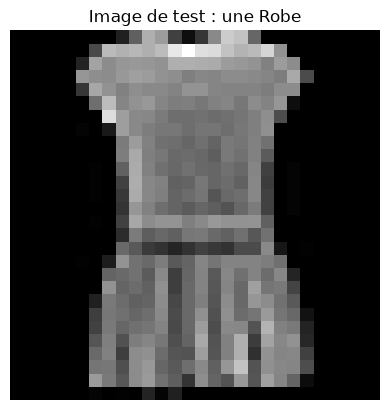

In [10]:
img = x_train[y_train ==3][0]
plt.imshow(img, cmap='gray')  # niveaux de gris
plt.title("Image de test : une Robe")
plt.axis("off")               # pas d'axes, pour une image propre
plt.show()

In [11]:
# 3) PRÉPARATION — normalisation + format attendu par Keras
x_train = np.expand_dims(x_train.astype("float32") / 255.0, -1)
x_test = np.expand_dims(x_test.astype("float32") / 255.0, -1)
print("Formes finales :", x_train.shape, x_test.shape)

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


In [12]:
# 4) LE RÉSEAU — encapsulé dans une classe

class CNNModel:
    def __init__(self):
        self.model = models.Sequential([
            Input(shape=(28, 28, 1)),
            layers.Conv2D(32, (3, 3), activation='relu'),
            layers.MaxPooling2D((2, 2)),
            layers.Conv2D(64, (3, 3), activation='relu'),
            layers.MaxPooling2D((2, 2)),
            layers.Conv2D(64, (3, 3), activation='relu'),
            layers.Flatten(),
            layers.Dense(128, activation='relu'),
            layers.Dropout(0.5),
            layers.Dense(10, activation="softmax"),
        ])

    def compile(self, **kwargs):
        self.model.compile(**kwargs)

    def fit(self, *args, **kwargs):
        return self.model.fit(*args, **kwargs)

    def evaluate(self, *args, **kwargs):
        return self.model.evaluate(*args, **kwargs)

    def predict(self, *args, **kwargs):
        return self.model.predict(*args, **kwargs)

    def summary(self):
        self.model.summary()

model = CNNModel()

In [13]:
# 5) COMPILATION — la méthode d'apprentissage

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# 6) ENTRAÎNEMENT — le réseau apprend de ses erreurs

history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.7575 - loss: 0.6608 - val_accuracy: 0.8407 - val_loss: 0.4191
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.8507 - loss: 0.4160 - val_accuracy: 0.8747 - val_loss: 0.3326
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.8734 - loss: 0.3504 - val_accuracy: 0.8878 - val_loss: 0.3041
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8876 - loss: 0.3124 - val_accuracy: 0.8977 - val_loss: 0.2727
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8971 - loss: 0.2860 - val_accuracy: 0.8972 - val_loss: 0.2778


In [15]:
# 7) EXAMEN FINAL — sur des images jamais vues

loss, acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\nPrécision sur le test : {acc * 100:.2f}%")

313/313 - 1s - 3ms/step - accuracy: 0.8992 - loss: 0.2833

Précision sur le test : 89.92%


  1/313 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


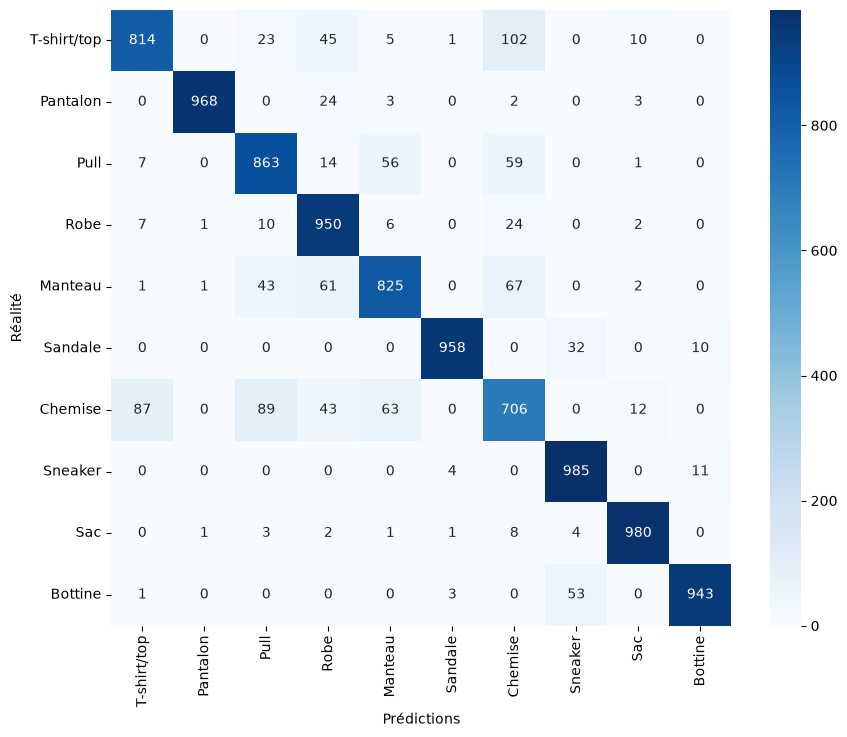

              precision    recall  f1-score   support

 T-shirt/top       0.89      0.81      0.85      1000
    Pantalon       1.00      0.97      0.98      1000
        Pull       0.84      0.86      0.85      1000
        Robe       0.83      0.95      0.89      1000
     Manteau       0.86      0.82      0.84      1000
     Sandale       0.99      0.96      0.97      1000
     Chemise       0.73      0.71      0.72      1000
     Sneaker       0.92      0.98      0.95      1000
         Sac       0.97      0.98      0.98      1000
     Bottine       0.98      0.94      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



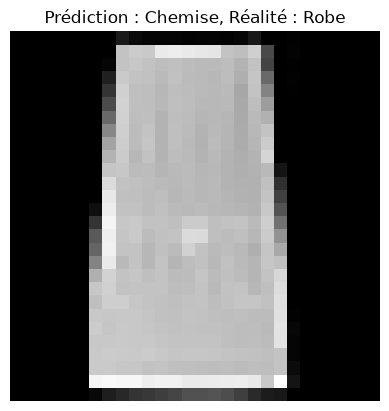

In [17]:
# 8) ANALYSE DES ERREURS

y_pred = np.argmax(model.predict(x_test), axis=-1)

# Matrice de confusion avec les noms
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes,
            yticklabels=classes)
plt.xlabel('Prédictions')
plt.ylabel("Réalité")
plt.show()

# Rapport de classification avec les noms
print(classification_report(y_test, y_pred, target_names=classes))

# Exemple avec les noms
plt.imshow(x_test[42].squeeze(), cmap='gray')
plt.title(f"Prédiction : {classes[y_pred[42]]}, Réalité : {classes[y_test[42]]}")
plt.axis("off")
plt.show()